In [69]:
import math
import pandas as pd
import seaborn
import matplotlib.pyplot as plt
import plotly.express as px
import squarify

international_teams = pd.read_csv("C:/Users/Christopher/Documents/GitHub/github-team/international_matches.csv")

international_teams.head(10)

,date,home_team,away_team,home_team_continent,away_team_continent,home_team_fifa_rank,away_team_fifa_rank,home_team_total_fifa_points,away_team_total_fifa_points,home_team_score,...,shoot_out,home_team_result,home_team_goalkeeper_score,away_team_goalkeeper_score,home_team_mean_defense_score,home_team_mean_offense_score,home_team_mean_midfield_score,away_team_mean_defense_score,away_team_mean_offense_score,away_team_mean_midfield_score
0,1993-08-08,Bolivia,Uruguay,South America,South America,59,22,0,0,3,...,No,Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1993-08-08,Brazil,Mexico,South America,North America,8,14,0,0,1,...,No,Draw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1993-08-08,Ecuador,Venezuela,South America,South America,35,94,0,0,5,...,No,Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1993-08-08,Guinea,Sierra Leone,Africa,Africa,65,86,0,0,1,...,No,Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1993-08-08,Paraguay,Argentina,South America,South America,67,5,0,0,1,...,No,Lose,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1993-08-08,Peru,Colombia,South America,South America,70,19,0,0,0,...,No,Lose,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1993-08-08,Zimbabwe,Eswatini,Africa,Africa,50,102,0,0,2,...,No,Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1993-08-09,Guinea,Sierra Leone,Africa,Africa,65,86,0,0,4,...,No,Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1993-08-11,Faroe Islands,Norway,Europe,Europe,111,9,0,0,0,...,No,Lose,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1993-08-11,Sweden,Switzerland,Europe,Europe,4,3,0,0,1,...,No,Lose,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Question 1: Since what year does the data set include games of?

Since the year 1993 there is international match information. Here is a visualization on how much data was given from matches every year


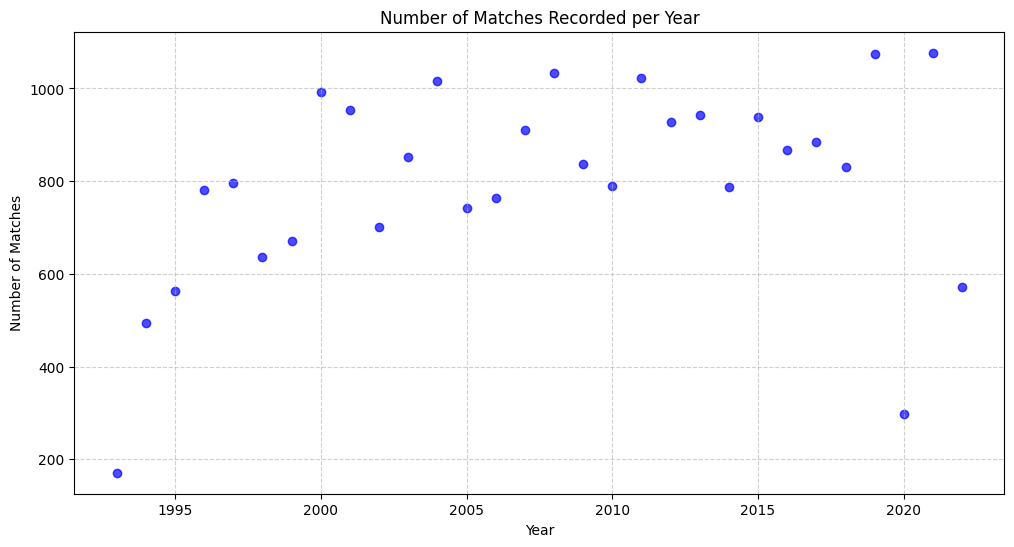

In [70]:
# converts string date values into datetime objects which allows for easier manipulation for dates
international_teams['date'] = pd.to_datetime(international_teams['date'], errors='coerce')

# checks for any missing dates
missing_dates = international_teams['date'].isna().sum()

# finds earliest date of recorded game only if there aren't any missing dates 
earliest_year = international_teams['date'].min().year if missing_dates == 0 else None

# prints since when the earliest year was for match information
print(f"Since the year {earliest_year} there is international match information. Here is a visualization on how much data was given from matches every year")

# gets column from dates and only gets year portion of dates
international_teams['year'] = international_teams['date'].dt.year

# count matches per year
matches_per_year = international_teams['year'].value_counts().sort_index()

# create scatter plot
plt.figure(figsize=(12,6))
plt.scatter(matches_per_year.index, matches_per_year.values, color="blue", alpha=0.7)

plt.title("Number of Matches Recorded per Year")
plt.xlabel("Year")
plt.ylabel("Number of Matches")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


Analyzing the data, it appears that the first set of games that we have a recording of for this data set is since 1993. Moreover, I also found it interesting the the amount of matches that were recorded and played throughout the most was around 2022. The trend of the matches played themselves continued to grow since 1993 until around 2019. Moving onto 2020, the amount of matches that were played dropped significantly. This almost matched the amount of recorded matches in 1993, only being a couple hundred off. The reason for this is because of the COVID-19 pandemic, which brought lockdown to the entire world and therefore, not many games were able to be played. Nonetheless, at the end of the graph the trend is starting to go back up, and many games were played throughout 2021 due to the lack of games there were the year before and to also prepare for the 2022 FIFA World Cup. The most games that were played were between 2005 and 2015, and it appears that the most matches played was in 2019/2021. 

Question 2: What are the top 10 home national teams from North America by wins?

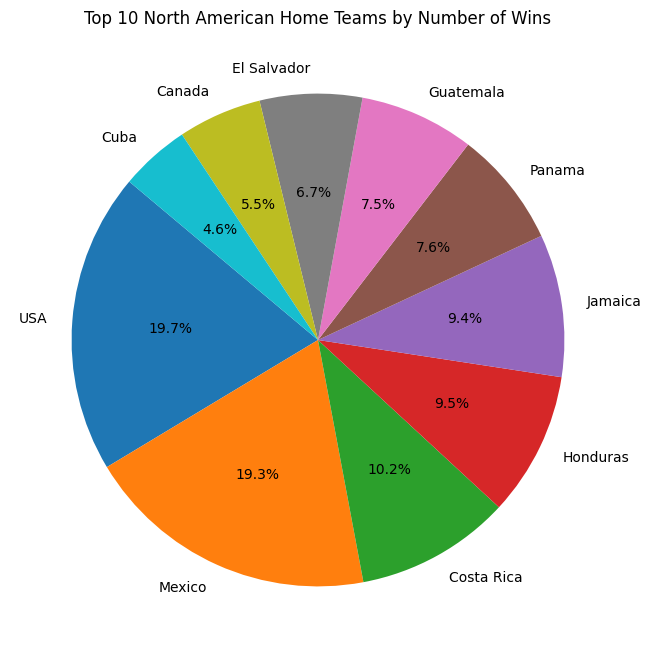

In [71]:
# Create a new column for winner
# Filter for North America
north_america_wins = international_teams[international_teams['home_team_continent'] == "North America"]
north_america_wins = north_america_wins [north_america_wins['home_team_result'] == 'Win']
north_america_wins.head(10)

top_na = north_america_wins['home_team'].value_counts()

# Limit to top 10 teams
top10_na = top_na.head(10)

# Pie chart
plt.figure(figsize=(8,8))
plt.pie(
    top10_na.values, 
    labels=top10_na.index, 
    autopct='%1.1f%%', 
    startangle=140
)

plt.title("Top 10 North American Home Teams by Number of Wins")
plt.show()



Analyzing the graph, it appears that the top ten home teams that have won in North America would be the USA, Mexico, Costa Rica, Honduras, Jamaica, Panama, Guatemala, El Salvador, Canada, and Cuba. Furthermore, the best team that continuously tends to win on their home turf would be the United States. Moreover, this doesn't specifically mean that the USA is the best team in the North American region, due to many other factors that come into play when determining who will be the home team. For example, the Gold Cup tournament that is played every two years is ONLY held in the USA, therefore every team that plays against the USA would be considered the away team. So, even though, for example, Mexico might have won playing the USA on their home turf, it wouldn't count torwards them being the best home team but instead the best away team. Nonetheless, based on the data we are given, the USA is the best home team in North America, based on wins. 

Question 3: What top 10 home national teams resulted in the match ending in a 'draw' the most?

home_team
Mexico            66
Japan             63
Bahrain           62
Oman              61
Qatar             60
Korea Republic    60
Jordan            57
USA               56
Kuwait            56
South Africa      54
Name: count, dtype: int64


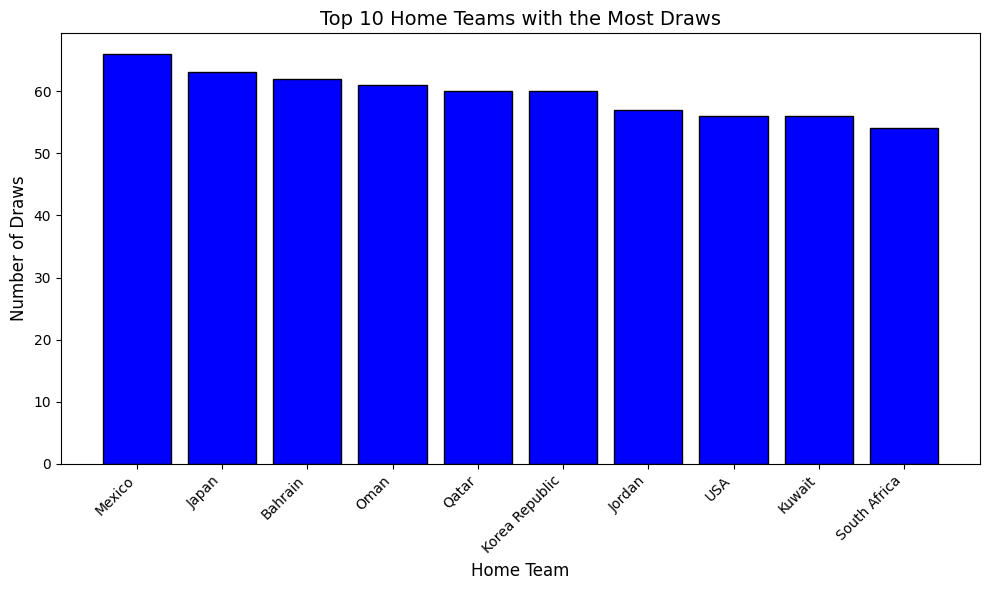

In [72]:
# Filter only draws based on home_team_result
draws = international_teams[international_teams['home_team_result'] == 'Draw']

# Count how many times each home team drew
home_draws = draws['home_team'].value_counts().head(10)

print(home_draws)

# Plot
plt.figure(figsize=(10,6))
plt.bar(home_draws.index, home_draws.values, color='blue', edgecolor='black')

# Labels
plt.title("Top 10 Home Teams with the Most Draws", fontsize=14)
plt.xlabel("Home Team", fontsize=12)
plt.ylabel("Number of Draws", fontsize=12)

# Rotate x labels for readability
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


Question 4: Out of all the FIFA World Cup matches that were played, what amount resulted in a penalty shootout? 

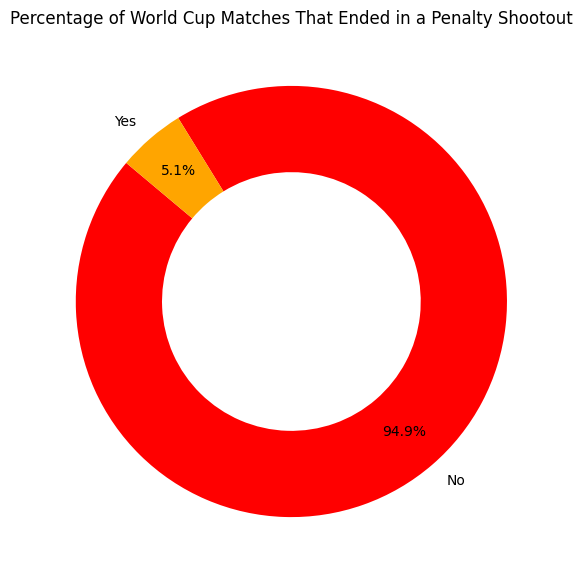

In [73]:
# Filter only World Cup matches
world_cup_matches = international_teams[international_teams['tournament'] == 'FIFA World Cup']

# Count matches by whether they ended in a shootout
shootout_counts = world_cup_matches['shoot_out'].value_counts()

# Calculate percentages
shootout_percentages = shootout_counts / shootout_counts.sum() * 100

plt.figure(figsize=(7,7))
plt.pie(
    shootout_percentages,
    labels=shootout_percentages.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['red', 'orange'],
    wedgeprops={'width':0.4},  
    pctdistance=0.8
)
plt.title("Percentage of World Cup Matches That Ended in a Penalty Shootout")
plt.show()


Question 5: With some of my soccer knowledge, I know that Brazil has won the most FIFA World Cups. Nonetheless, does the pattern in their winnings suggest that they will continue to win their future games as the home team do their winnings in the most World Cups not show a correlation between game wins? 

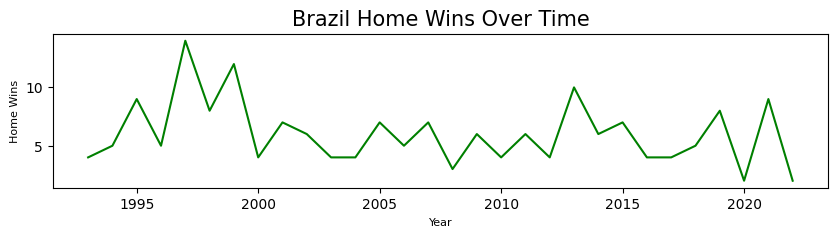

In [74]:
# Ensure date column is datetime
international_teams['date'] = pd.to_datetime(international_teams['date'])

brazil_home_matches = international_teams[international_teams['home_team'] == 'Brazil'].copy()

# Now it’s safe to add new columns
brazil_home_matches['home_win'] = brazil_home_matches['home_team_result'] == 'Win'
brazil_home_matches['year'] = brazil_home_matches['date'].dt.year

# Count home wins per year
wins_by_year = brazil_home_matches.groupby('year')['home_win'].sum()

plt.figure(figsize=(10,2))  # compact, horizontal
plt.plot(wins_by_year, color='green', linewidth=1.5)

plt.xlabel('Year', fontsize=8)
plt.ylabel('Home Wins', fontsize=8)
plt.title('Brazil Home Wins Over Time', fontsize=15)
plt.grid(False)
plt.show()


As seen by the graph, it appears that despite Brazil holding the title for the most FIFA World Cups in history, they have fluctuated very much in an attempt to win their games as the home team throughout the years. It appears that they won the most games throughout the late 1990s and early 2000s. After that, unfortunately the trend on their wins has gone down. As mentioned before, althought there are many factors that come into play such as amount of games they play, players that might be injured, etc., just because they have the most World Cups won doesn't necessarily mean that they will win the next World Cup. This reminds be of 2014 group stage match between Spain and the Netherlands. With both of them playing against each other in the final of 2010 and Spain being victorious, the group stage match, the first match for both teams in the 2014 World Cup, resulted in a dominating score of the Netherlands winning 1-5. This shows that not every game is the same, which is the amazing thing about soccer. Every game is different, and even the teams that are thought to be underdogs may end up victorious. 

Question 6: What countries are the games most played in?

In [75]:
# Count matches per country
games_per_country = international_teams['country'].value_counts().reset_index()
games_per_country.columns = ['country', 'matches']

print(games_per_country.head(10))  # Top 10 countries with most games

# Geo chart
fig = px.scatter_geo(
    games_per_country,
    locations="country",
    locationmode="country names",  # matches country names
    size="matches",                # bubble size based on number of matches
    hover_name="country",          # hover label
    size_max=40,                   # max bubble size
    projection="natural earth",    # map style
    title="International Matches Played by Country (Bubble Chart)"
)

fig.show()

                country  matches
0                   USA     1003
1          South Africa      505
2  United Arab Emirates      462
3                 Qatar      461
4                France      445
5               Germany      285
6              Thailand      280
7          Saudi Arabia      280
8               England      277
9                 Japan      277


C:\Users\Christopher\AppData\Local\Temp\ipykernel_41908\3591805207.py:8: DeprecationWarning:

The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.



After analyzing the data and geo bubble chart, it appears that the countries that games are played in the most is USA, South Africa, United Arab Emirates, and Qatar. Moreover, the country that gets the most games played in would be the USA. Nonetheless, after analyzing the geo bubble chart itself, it appears that if we were to compare the games played through continent, Europe is the clear winner. As mentioned in the previous response, since the USA is the size of a couple of European countries combined, it will definitely hold more matches played by country. But by looking at the continents, France itself already gets almost half the amount of matches played in the USA. Hovering over the rest of the countries in Europe, it is clear that comparing matches played by continent, Europe is the clear winner. This is especially due to the tournaments that are played, specifically the World Cup, mostly being held in Europe. 

Question 7: Do the top three national teams from Europe score more goals while they’re the home or away team?

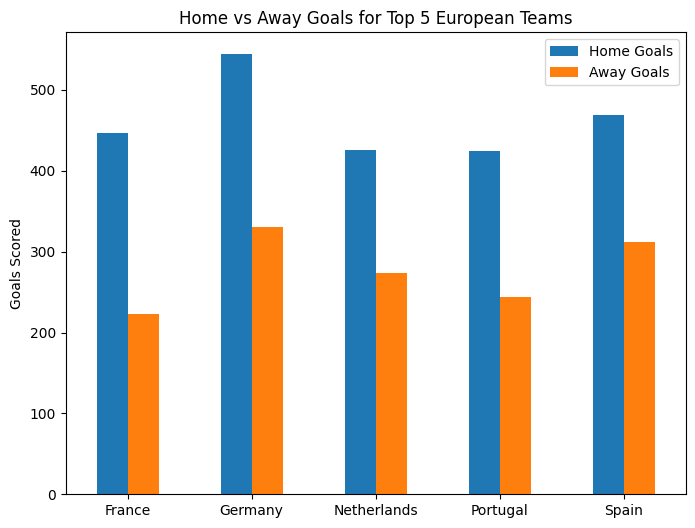

In [76]:
# Filter matches where either team is from North America
eu_matches = international_teams[(international_teams['home_team_continent'] == "Europe") | 
                (international_teams['away_team_continent'] == "Europe")]

# Calculate total goals scored by each European team
home_goals = eu_matches[eu_matches['home_team_continent'] == "Europe"].groupby('home_team')['home_team_score'].sum()
away_goals = eu_matches[eu_matches['away_team_continent'] == "Europe"].groupby('away_team')['away_team_score'].sum()

# Combine home and away goals to get total goals per team
total_goals = home_goals.add(away_goals, fill_value=0).sort_values(ascending=False)

# Get top 3 North American teams
top_eu_teams = total_goals.head(5)
top_eu_teams

# Home goals for top 3 teams
home_goals_top = eu_matches[eu_matches['home_team'].isin(top_eu_teams.index)].groupby('home_team')['home_team_score'].sum()

# Away goals for top 3 teams
away_goals_top = eu_matches[eu_matches['away_team'].isin(top_eu_teams.index)].groupby('away_team')['away_team_score'].sum()

# Combine into a DataFrame for easy comparison
home_away_comparison = pd.DataFrame({
    'Home Goals': home_goals_top,
    'Away Goals': away_goals_top
}).fillna(0).astype(int)

# Create a bar chart
home_away_comparison.plot(kind='bar', figsize=(8,6))

# Add labels and title
plt.ylabel("Goals Scored")
plt.title("Home vs Away Goals for Top 5 European Teams")
plt.xticks(rotation=0)  # Keep team names horizontal
plt.show()

I decided to filter this question only for European teams, due to the past couple of years of the World Cup only being win by European teams. I also decided to expand the amount of teams being looked at from three originally to five. Looking at the graph itself, it appears that, as I presumed, the teams that played on their home turf scored the most goals. This is due to these teams being more used to playing at the location they mostly play in. Factors such as elevation, fans, surface type, and much more can lead them to being more confident and scoring more goals. Nonetheless, I also wanted to compare how these teams play as an away team. It appears that Germany scores the most goals as the away team compared to the other top five European countries. I specifically wanted to bring light to this because these European teams will be playing as the away team in the 2026 World Cup, since it's being held in the USA, Mexico, and Canada. If the team tends to score more goals as the away team, they will most likely be able to do this at the World Cup, increasing their chances in winning this tournament. Regardless, to answer the question, the top five European teams score the most goals as the home team. 

Question 8: What were the best ranked national teams throughout 2022?

In [77]:
# Ensure 'date' column is datetime
international_teams['date'] = pd.to_datetime(international_teams['date'])

# Filter for 2022 matches only
matches_2022 = international_teams[international_teams['date'].dt.year == 2022]

# Collect FIFA rankings for home and away teams
home_ranks = matches_2022[['home_team', 'home_team_fifa_rank']].rename(
    columns={'home_team': 'team', 'home_team_fifa_rank': 'rank'}
)

away_ranks = matches_2022[['away_team', 'away_team_fifa_rank']].rename(
    columns={'away_team': 'team', 'away_team_fifa_rank': 'rank'}
)

# Combine into a single DataFrame
all_ranks = pd.concat([home_ranks, away_ranks], ignore_index=True)

# Get the best (lowest) observed rank per team in 2022
team_best_ranks = all_ranks.groupby('team')['rank'].min().reset_index()

# Sort by rank
team_best_ranks = team_best_ranks.sort_values('rank')

print(team_best_ranks.head(10))

top_10 = team_best_ranks.head(10)

fig = px.bar(
    top_10,
    x='rank',
    y='team',
    orientation='h',
    title='Top FIFA Teams by Best Ranking in 2022 (including ties)',
    text='rank'
)
fig.update_layout(yaxis={'categoryorder':'total ascending'})
fig.show()


          team  rank
25      Brazil     1
18     Belgium     1
67      France     3
7    Argentina     4
59     England     5
90       Italy     6
163      Spain     7
143   Portugal     8
52     Denmark     9
116     Mexico     9


The stacked bar chart itself might look weird, as there is no number two rank included. Nonetheless, after analyzing the data, this is due to Belgium fluctuating in ranking, occasionally being number one and two throughout the year 2022. This can happen due to a number of reasons: either the team would win/lose games, other teams would have more wins compared to them, how many games were played, and more. Nonetheless, when analyzing the data through here, the top three teams that stayed the most consistent in their rankings were Brazil, Belgium, and France, where Brazil and Belgium were fighting for that number one spot. As for the last spots on the rankings, it looks like Mexico and Denmark were fighting for the number nine spot. 

Question 9: What are the most played soccer tournaments in the world? 

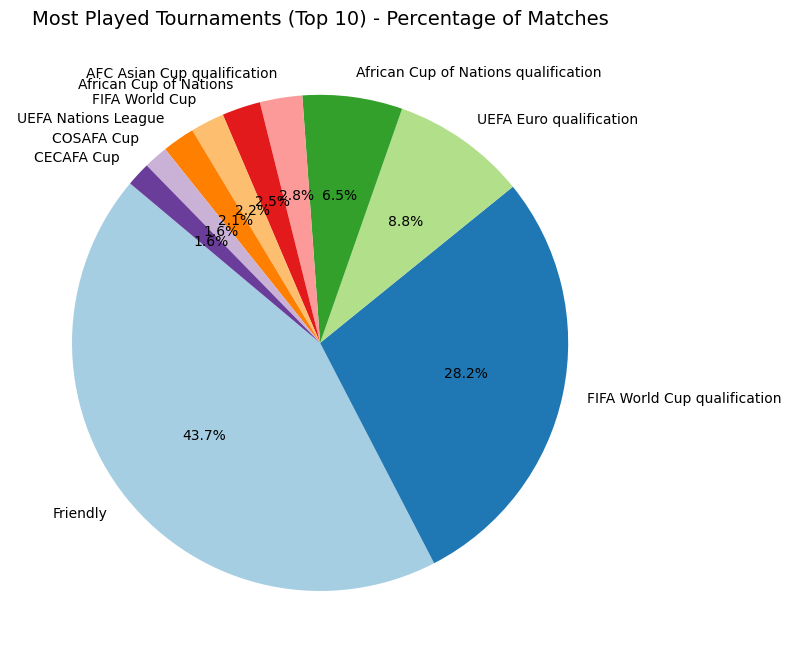

In [78]:
# Find the most played tournament by counting occurrences in the 'tournament' column
most_played_tournaments = international_teams['tournament'].value_counts().head(10)
most_played_tournaments

# Calculate percentages of the top 10 tournaments
tournament_percentages = (most_played_tournaments / most_played_tournaments.sum()) * 100

# Plot pie chart of the top 10 tournaments by percentage
plt.figure(figsize=(8, 8))
plt.pie(
    tournament_percentages,
    labels=tournament_percentages.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=plt.cm.Paired.colors
)

plt.title("Most Played Tournaments (Top 10) - Percentage of Matches", fontsize=14)
plt.tight_layout()
plt.show()


Based on the pie chart and data set, the most played "tournament" would be friendlies. Although this isn't techincally counsidered a tournament, they are extremely important for national teams to take advantage of these in order to prepare for the rest of the tournaments shown on the pie chart such as the FIFA World Cup Qualifiers, UEFA Euro Qualifiers, and most importantly, the FIFA World Cup. I would also like to point out that regardless of which tournaments are played the most, this wouldn't be related to popularity at all. In fact, the most popular tournament in the entire world occurs every four years, which would be the FIFA World Cup. Although the percentage of games of these is on the lower side, the reason for this is due to how often the tournament itself is played and why, again, friendlies are extremely important for national teams: for them to prepare for crucial tournaments such as this one. 

Question 10: What team has won the most international games?

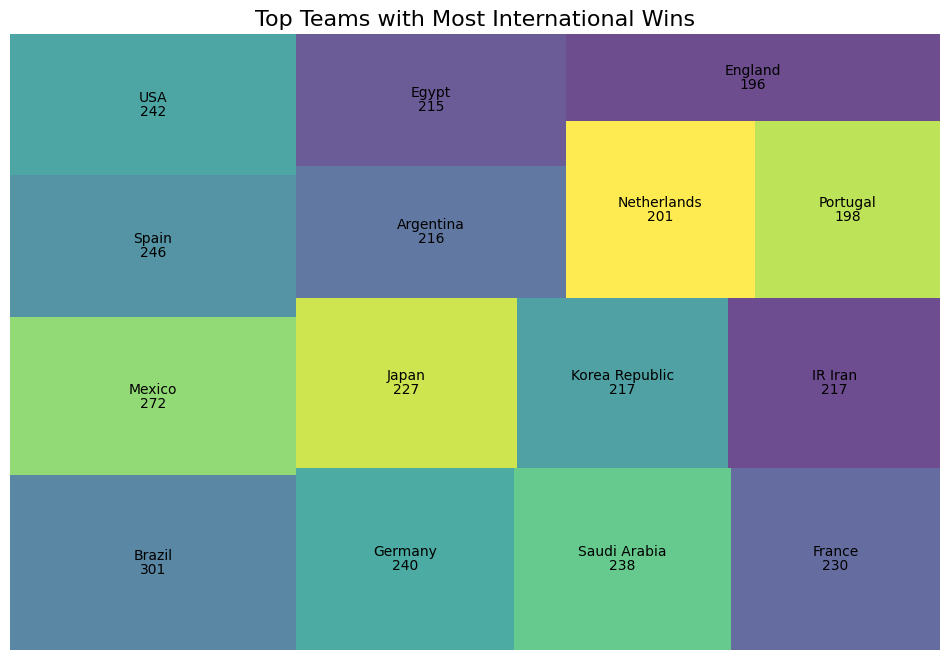

In [79]:
# Filter matches where a team won
wins = international_teams[international_teams["home_team_result"] == "Win"].copy()

# Count wins for home teams
home_wins = international_teams[international_teams["home_team_result"] == "Win"]["home_team"].value_counts()

# Count wins for away teams (when home team result = Lose, then away team won)
away_wins = international_teams[international_teams["home_team_result"] == "Lose"]["away_team"].value_counts()

# Combine both
total_wins = home_wins.add(away_wins, fill_value=0).astype(int)

# Find the top 10 teams with most wins
top_winning_teams = total_wins.sort_values(ascending=False).head(15)
top_winning_teams

# Plot tree map
plt.figure(figsize=(12, 8))
squarify.plot(
    sizes=top_winning_teams.values,
    label=top_winning_teams.index,
    value=top_winning_teams.values,
    alpha=0.8
)
plt.title("Top Teams with Most International Wins", fontsize=16)
plt.axis("off")
plt.show()



Using the data set and graph created, it appears that the top five international teams that have the most international wins would be, Brazil, Mexico, Spain, USA, and Germany. 